In [14]:
import pandas as pd
import numpy as np

df = pd.read_csv("sales_data.csv")

print(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns)
df.info()
print(df.describe())

   OrderID Customer   Product     OrderDate  Quantity UnitPrice     Region
0      101   pooja     Laptop    2026-10-01       1.0     55000   chennai 
1      102     ARUN     Mouse    2026-10-02       2.0       500    Chennai
2      103    priya  Keyboard    2026-10-03       1.0      1500  Bangalore
3      104     Ravi   Monitor  invalid-date       2.0     12000    chennai
4      105      ANU     Mouse    2026-10-05       3.0       500      Delhi
Shape: (12, 7)
Columns: Index(['OrderID', 'Customer', 'Product', 'OrderDate', 'Quantity', 'UnitPrice',
       'Region'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   OrderID    12 non-null     int64  
 1   Customer   12 non-null     object 
 2   Product    12 non-null     object 
 3   OrderDate  12 non-null     object 
 4   Quantity   11 non-null     float64
 5   UnitPrice  12 non-nu

In [16]:
original_df = pd.read_csv("sales_data.csv")

original_df["Customer"] = (
    original_df["Customer"].str.strip().str.casefold()
)
original_df["Product"] = (
    original_df["Product"].str.strip().str.casefold()
)
original_df["Region"] = (
    original_df["Region"].str.strip().str.casefold()
)
duplicate_rows = original_df[
    original_df.duplicated(
        subset=[
            "Customer", "Product", "OrderDate",
            "Quantity", "UnitPrice", "Region"
        ],
        keep=False
    )
]
print(duplicate_rows)
print(original_df.isnull().sum())
print(original_df.duplicated().sum())

   OrderID Customer Product   OrderDate  Quantity UnitPrice   Region
0      101    pooja  laptop  2026-10-01       1.0     55000  chennai
5      106    pooja  laptop  2026-10-01       1.0     55000  chennai
OrderID      0
Customer     0
Product      0
OrderDate    0
Quantity     1
UnitPrice    0
Region       0
dtype: int64
0


In [17]:
df=df.drop_duplicates()
df["Customer"] =df["Customer"].str.strip().str.title()
df["Region"] =df["Region"].str.strip().str.title()
df["Product"] =df["Product"].str.strip().str.title()
df["OrderDate"] = pd.to_datetime(
    df["OrderDate"], errors="coerce"
)
df["Quantity"] = pd.to_numeric(
    df["Quantity"], errors="coerce"
)
df["UnitPrice"] = pd.to_numeric(
    df["UnitPrice"], errors="coerce"
)

In [18]:
print(df.dtypes)
print(df.isnull().sum())

OrderID               int64
Customer             object
Product              object
OrderDate    datetime64[ns]
Quantity            float64
UnitPrice           float64
Region               object
dtype: object
OrderID      0
Customer     0
Product      0
OrderDate    2
Quantity     1
UnitPrice    1
Region       0
dtype: int64


In [19]:
df["Quantity"] = df["Quantity"].fillna(
    df["Quantity"].median()
)

In [20]:
Q1 = df["UnitPrice"].quantile(0.25)
Q3 = df["UnitPrice"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
outliers = df[
    (df["UnitPrice"] < lower_bound) |
    (df["UnitPrice"] > upper_bound)
]
print(outliers)

Q1: 500.0
Q3: 33500.0
IQR: 33000.0
Lower bound: -49000.0
Upper bound: 83000.0
   OrderID Customer Product  OrderDate  Quantity  UnitPrice Region
9      110    Divya  Laptop 2026-10-10       1.0   999999.0  Delhi


<Axes: >

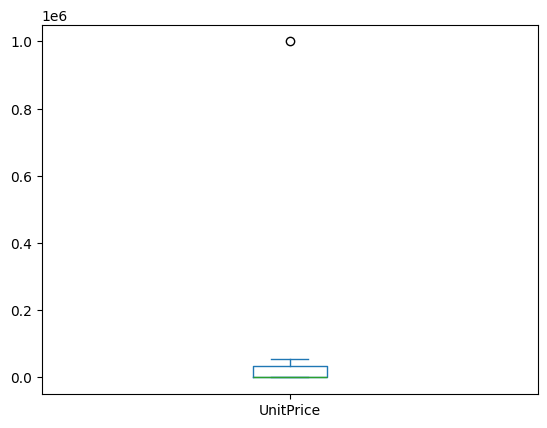

In [21]:
df["UnitPrice"].plot(kind="box")

In [22]:
df["TotalAmount"] = df["Quantity"] * df["UnitPrice"]
print(df[["Product", "Quantity", "UnitPrice", "TotalAmount"]])

     Product  Quantity  UnitPrice  TotalAmount
0     Laptop       1.0    55000.0      55000.0
1      Mouse       2.0      500.0       1000.0
2   Keyboard       1.0     1500.0       1500.0
3    Monitor       2.0    12000.0      24000.0
4      Mouse       3.0      500.0       1500.0
5     Laptop       1.0    55000.0      55000.0
6   Keyboard       2.0     1500.0       3000.0
7    Monitor       2.0        NaN          NaN
8      Mouse       2.0      500.0       1000.0
9     Laptop       1.0   999999.0     999999.0
10  Keyboard       2.0     1500.0       3000.0
11   Monitor       1.0     -100.0       -100.0


In [23]:
def categorize_price(price):
    if pd.isna(price) or price < 0:
        return "Unknown"
    elif price >= 10000:
        return "High"
    else:
        return "Low"
df["PriceCategory"] = df["UnitPrice"].apply(
    categorize_price
)
print(df[["UnitPrice", "PriceCategory"]])

    UnitPrice PriceCategory
0     55000.0          High
1       500.0           Low
2      1500.0           Low
3     12000.0          High
4       500.0           Low
5     55000.0          High
6      1500.0           Low
7         NaN       Unknown
8       500.0           Low
9    999999.0          High
10     1500.0           Low
11     -100.0       Unknown


In [24]:
print(df[df["UnitPrice"] < 0])
print(df[df["OrderDate"].isna()])
print(df.groupby("Region")["TotalAmount"].sum())
print(df.sort_values("TotalAmount", ascending=False))

    OrderID Customer  Product OrderDate  Quantity  UnitPrice     Region  \
11      112     Sara  Monitor       NaT       1.0     -100.0  Bangalore   

    TotalAmount PriceCategory  
11       -100.0       Unknown  
    OrderID Customer  Product OrderDate  Quantity  UnitPrice     Region  \
3       104     Ravi  Monitor       NaT       2.0    12000.0    Chennai   
11      112     Sara  Monitor       NaT       1.0     -100.0  Bangalore   

    TotalAmount PriceCategory  
3       24000.0          High  
11       -100.0       Unknown  
Region
Bangalore       1400.0
Chennai       139000.0
Delhi        1001499.0
Hyderabad       3000.0
Name: TotalAmount, dtype: float64
    OrderID Customer   Product  OrderDate  Quantity  UnitPrice     Region  \
9       110    Divya    Laptop 2026-10-10       1.0   999999.0      Delhi   
0       101    Pooja    Laptop 2026-10-01       1.0    55000.0    Chennai   
5       106    Pooja    Laptop 2026-10-01       1.0    55000.0    Chennai   
3       104     Ravi  

In [25]:
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df.dtypes)
print("Negative prices:", (df["UnitPrice"] < 0).sum())
print("Negative quantities:", (df["Quantity"] < 0).sum())
print(df[[
    "Quantity", "UnitPrice",
    "TotalAmount", "PriceCategory"
]].head())
df.to_csv("cleaned_sales_data.csv", index=False)

OrderID          0
Customer         0
Product          0
OrderDate        2
Quantity         0
UnitPrice        1
Region           0
TotalAmount      1
PriceCategory    0
dtype: int64
Duplicates: 0
OrderID                   int64
Customer                 object
Product                  object
OrderDate        datetime64[ns]
Quantity                float64
UnitPrice               float64
Region                   object
TotalAmount             float64
PriceCategory            object
dtype: object
Negative prices: 1
Negative quantities: 0
   Quantity  UnitPrice  TotalAmount PriceCategory
0       1.0    55000.0      55000.0          High
1       2.0      500.0       1000.0           Low
2       1.0     1500.0       1500.0           Low
3       2.0    12000.0      24000.0          High
4       3.0      500.0       1500.0           Low
